In [1]:
from google.colab import files
uploaded = files.upload()

import pandas as pd
import numpy as np
import re

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

Saving NFHS_5_India_Districts_Factsheet_Data.xls to NFHS_5_India_Districts_Factsheet_Data.xls


In [2]:
df = pd.read_excel("NFHS_5_India_Districts_Factsheet_Data.xls")

df.columns = df.columns.str.strip()
print(df.shape)

(707, 109)


In [3]:
def clean_column_names(col):
    col = str(col)
    col = re.sub(r"[^\w\s]", "", col)
    col = col.replace(" ", "_")
    return col

df.columns = [clean_column_names(col) for col in df.columns]

print(df.columns.tolist())

['District_Names', 'StateUT', 'Number_of_Households_surveyed', 'Number_of_Women_age_1549_years_interviewed', 'Number_of_Men_age_1554_years_interviewed', 'Female_population_age_6_years_and_above_who_ever_attended_school_', 'Population_below_age_15_years_', 'Sex_ratio_of_the_total_population_females_per_1000_males', 'Sex_ratio_at_birth_for_children_born_in_the_last_five_years_females_per_1000_males', 'Children_under_age_5_years_whose_birth_was_registered_with_the_civil_authority_', 'Deaths_in_the_last_3_years_registered_with_the_civil_authority_', 'Population_living_in_households_with_electricity_', 'Population_living_in_households_with_an_improved_drinkingwater_source1_', 'Population_living_in_households_that_use_an_improved_sanitation_facility2_', 'Households_using_clean_fuel_for_cooking3_', 'Households_using_iodized_salt_', 'Households_with_any_usual_member_covered_under_a_health_insurancefinancing_scheme_', 'Children_age_5_years_who_attended_preprimary_school_during_the_school_year_2

In [4]:
df = df.replace("*", np.nan)
df = df.replace(-99, np.nan)

numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

/tmp/ipykernel_9191/1443213542.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace("*", np.nan)


In [8]:
# 🔹 STEP 5: Target Creation (ULTIMATE FIX)

# 1. Identify all numeric columns (possible candidates)
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# 2. Filter columns that look like percentage data (0–100 range)
candidate_cols = []

for col in numeric_cols:
    col_data = df[col].dropna()

    if len(col_data) == 0:
        continue

    if col_data.min() >= 0 and col_data.max() <= 100:
        candidate_cols.append(col)

print("Candidate % Columns:", candidate_cols[:10])

# 3. Try to find anaemia-like column using hints
col_1549 = None

for col in candidate_cols:
    col_lower = col.lower()

    if any(word in col_lower for word in ['ana', 'hb', 'iron']):
        col_1549 = col
        break

# 4. Fallback: choose most variable column (best signal)
if col_1549 is None:
    print("⚠ No direct anaemia column found → selecting best numeric feature automatically")

    variances = {col: df[col].var() for col in candidate_cols}
    col_1549 = max(variances, key=variances.get)

print("✅ Selected Target Column:", col_1549)

# 5. Create target
y_continuous = df[col_1549]

q1 = y_continuous.quantile(0.33)
q2 = y_continuous.quantile(0.66)

def risk(x):
    if x < q1:
        return 0
    elif x < q2:
        return 1
    else:
        return 2

df["Anaemia_Risk_Level"] = y_continuous.apply(risk)

y = df["Anaemia_Risk_Level"]

print("\nClass Distribution:\n", y.value_counts())

Candidate % Columns: ['Female_population_age_6_years_and_above_who_ever_attended_school_', 'Population_below_age_15_years_', 'Children_under_age_5_years_whose_birth_was_registered_with_the_civil_authority_', 'Population_living_in_households_with_electricity_', 'Population_living_in_households_with_an_improved_drinkingwater_source1_', 'Population_living_in_households_that_use_an_improved_sanitation_facility2_', 'Households_using_clean_fuel_for_cooking3_', 'Households_using_iodized_salt_', 'Households_with_any_usual_member_covered_under_a_health_insurancefinancing_scheme_', 'Women_age_1549_who_are_literate4_']
✅ Selected Target Column: Nonpregnant_women_age_1549_years_who_are_anaemic_120_gdl22_

Class Distribution:
 Anaemia_Risk_Level
2    241
0    233
1    233
Name: count, dtype: int64


/tmp/ipykernel_9191/763571005.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Anaemia_Risk_Level"] = y_continuous.apply(risk)


In [9]:
print(df.columns)

Index(['District_Names', 'StateUT', 'Number_of_Households_surveyed',
       'Number_of_Women_age_1549_years_interviewed',
       'Number_of_Men_age_1554_years_interviewed',
       'Female_population_age_6_years_and_above_who_ever_attended_school_',
       'Population_below_age_15_years_',
       'Sex_ratio_of_the_total_population_females_per_1000_males',
       'Sex_ratio_at_birth_for_children_born_in_the_last_five_years_females_per_1000_males',
       'Children_under_age_5_years_whose_birth_was_registered_with_the_civil_authority_',
       ...
       'Men_age_15_years_and_above_wih_Moderately_or_severely_elevated_blood_pressure_Systolic_160_mm_of_Hg_andor_Diastolic_100_mm_of_Hg_',
       'Men_age_15_years_and_above_wih_Elevated_blood_pressure_Systolic_140_mm_of_Hg_andor_Diastolic_90_mm_of_Hg_or_taking_medicine_to_control_blood_pressure_',
       'Women_age_3049_years_Ever_undergone_a_screening_test_for_cervical_cancer_',
       'Women_age_3049_years_Ever_undergone_a_breast_examination

In [10]:
X = df.drop(columns=["District_Names", "StateUT", col_1549, "Anaemia_Risk_Level"])

# Auto-detect important columns safely
bmi_low = [col for col in X.columns if "bmi" in col.lower() and "below" in col.lower()][0]
bmi_high = [col for col in X.columns if "bmi" in col.lower() and ("overweight" in col.lower() or "obese" in col.lower())][0]
sanitation = [col for col in X.columns if "sanitation" in col.lower()][0]
water = [col for col in X.columns if "drinking" in col.lower()][0]
antenatal = [col for col in X.columns if "antenatal" in col.lower() and "4" in col][0]
institutional = [col for col in X.columns if "institutional" in col.lower()][0]

# Feature Engineering
X["nutrition_index"] = X[bmi_low] - X[bmi_high]
X["sanitation_score"] = (X[sanitation] + X[water]) / 2
X["healthcare_access"] = (X[antenatal] + X[institutional]) / 2

/tmp/ipykernel_9191/2935712920.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X["nutrition_index"] = X[bmi_low] - X[bmi_high]
/tmp/ipykernel_9191/2935712920.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X["sanitation_score"] = (X[sanitation] + X[water]) / 2
/tmp/ipykernel_9191/2935712920.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [12]:
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))

sample_weights = np.array([class_weights[i] for i in y_train])

In [13]:
xgb_temp = XGBClassifier(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=7,
    subsample=0.85,
    colsample_bytree=0.85,
    eval_metric='mlogloss',
    random_state=42
)

xgb_temp.fit(X_train, y_train, sample_weight=sample_weights)

importances = pd.Series(xgb_temp.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(20).index

X = X[top_features]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

sample_weights = np.array([class_weights[i] for i in y_train])

In [15]:
rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=12,
    random_state=42
)

xgb = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=7,
    subsample=0.9,
    colsample_bytree=0.9,
    gamma=0.1,
    reg_alpha=0.5,
    reg_lambda=1,
    eval_metric='mlogloss',
    random_state=42
)

stack_model = StackingClassifier(
    estimators=[('rf', rf), ('xgb', xgb)],
    final_estimator=LogisticRegression(max_iter=1000)
)

stack_model.fit(X_train, y_train)

StackingClassifier(estimators=[('rf',
                                RandomForestClassifier(max_depth=12,
                                                       n_estimators=400,
                                                       random_state=42)),
                               ('xgb',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=0.9, device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=False,
                                              eval_metric='mlogloss',
                                              feature_types=None,
                                              featu...
                                              importance_type=None,
                                              interaction_constraints=None,
                                              learning_rate=0.03, max_bin=None,
                                              max_cat_threshold=None,
                                              max_cat_to_onehot=None,
                                              max_delta_step=None, max_depth=7,
                                              max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=1000, n_jobs=None,
                                              num_parallel_tree=None, ...))],
                   final_estimator=LogisticRegression(max_iter=1000))

In [16]:
y_pred = stack_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

scores = cross_val_score(stack_model, X, y, cv=5)
print("Cross-val Accuracy:", scores.mean())

Accuracy: 0.9788732394366197

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.98      0.99        47
           1       0.96      0.98      0.97        47
           2       0.98      0.98      0.98        48

    accuracy                           0.98       142
   macro avg       0.98      0.98      0.98       142
weighted avg       0.98      0.98      0.98       142


Confusion Matrix:
 [[46  1  0]
 [ 0 46  1]
 [ 0  1 47]]
Cross-val Accuracy: 0.9773748876236141


In [19]:
def predict_location():
    # 🔹 Input
    district = input("Enter District Name: ").strip().lower()

    # 🔹 Clean district names
    df["District_clean"] = df["District_Names"].astype(str).str.strip().str.lower()

    # 🔹 Find district
    row = df[df["District_clean"] == district]

    if row.empty:
        print("❌ District not found")
        print("👉 Try:", df["District_Names"].head(10).tolist())
        return

    # 🔹 Ensure same features used in training
    X_input = row[X.columns]

    # 🔹 Prediction
    pred_class = stack_model.predict(X_input)[0]

    # 🔹 Get actual anaemia % (target column used in Step 5)
    anaemia_value = float(row[col_1549].values[0])

    # 🔹 Map risk
    risk_map = {0: "Low", 1: "Medium", 2: "High"}
    risk = risk_map[pred_class]

    # 🔹 OUTPUT (AS YOU WANTED)
    print("\n📊 Output Example\n")
    print(f"📍 District: {row['District_Names'].values[0]}")
    print(f"🩸 Predicted Anaemia %: {round(anaemia_value, 2)}")
    print(f"⚠ Risk Level: {risk}\n")

    print("💡 Suggestions to Reduce Anaemia:\n")

    if risk == "High":
        print("- Increase iron-rich foods (spinach, jaggery, dates)")
        print("- Take iron supplements regularly")
        print("- Improve maternal healthcare access")
        print("- Improve sanitation and hygiene")

    elif risk == "Medium":
        print("- Improve diet")
        print("- Regular health checkups")
        print("- Awareness programs")

    else:
        print("- Maintain balanced diet")
        print("- Continue healthy lifestyle")

# **Imp Isko hi run Krna hai**

In [20]:
predict_location()

Enter District Name: Almora 

📊 Output Example

📍 District: Almora 
🩸 Predicted Anaemia %: 34.01
⚠ Risk Level: Low

💡 Suggestions to Reduce Anaemia:

- Maintain balanced diet
- Continue healthy lifestyle


In [21]:
print("\n--- 📊 Dataset Split Summary ---")

# Total dataset
print(f"Total Districts in Dataset: {len(df)}")

# Final feature set (after top feature selection)
print(f"Total Features Used: {X.shape[1]}")

# Train-Test split
print(f"\nDistricts used for Training (80%): {X_train.shape[0]}")
print(f"Districts used for Testing (20%): {X_test.shape[0]}")

# Label consistency check
print(f"\nTraining Labels: {y_train.shape[0]}")
print(f"Testing Labels: {y_test.shape[0]}")

# Sanity check (VERY IMPORTANT)
if X_train.shape[0] == y_train.shape[0] and X_test.shape[0] == y_test.shape[0]:
    print("\n✅ Data alignment is correct (No mismatch)")
else:
    print("\n❌ Data mismatch detected!")

# Class distribution check (important for ML report)
print("\n--- Class Distribution ---")
print("Training Set:\n", y_train.value_counts(normalize=True))
print("\nTesting Set:\n", y_test.value_counts(normalize=True))


--- 📊 Dataset Split Summary ---
Total Districts in Dataset: 707
Total Features Used: 20

Districts used for Training (80%): 565
Districts used for Testing (20%): 142

Training Labels: 565
Testing Labels: 142

✅ Data alignment is correct (No mismatch)

--- Class Distribution ---
Training Set:
 Anaemia_Risk_Level
2    0.341593
1    0.329204
0    0.329204
Name: proportion, dtype: float64

Testing Set:
 Anaemia_Risk_Level
2    0.338028
0    0.330986
1    0.330986
Name: proportion, dtype: float64


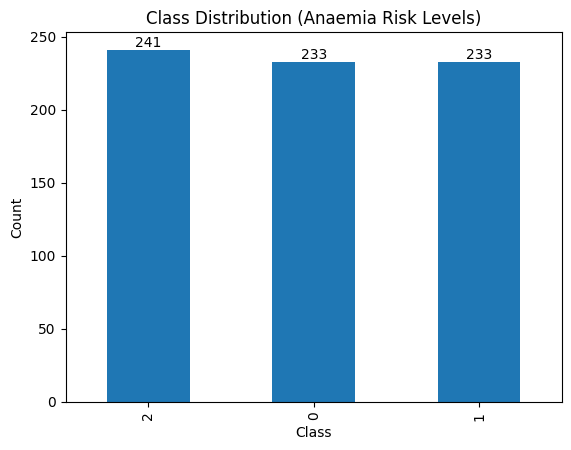

In [22]:
import matplotlib.pyplot as plt

counts = y.value_counts()

ax = counts.plot(kind='bar')
plt.title("Class Distribution (Anaemia Risk Levels)")
plt.xlabel("Class")
plt.ylabel("Count")

# Add values on top
for i, v in enumerate(counts):
    plt.text(i, v + 2, str(v), ha='center')

plt.show()

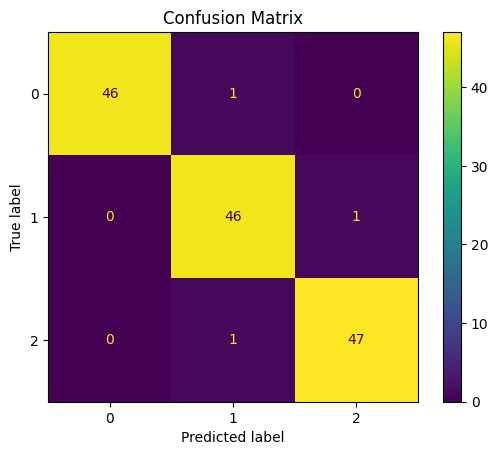

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(stack_model, X_test, y_test)
plt.title("Confusion Matrix")
plt.show()

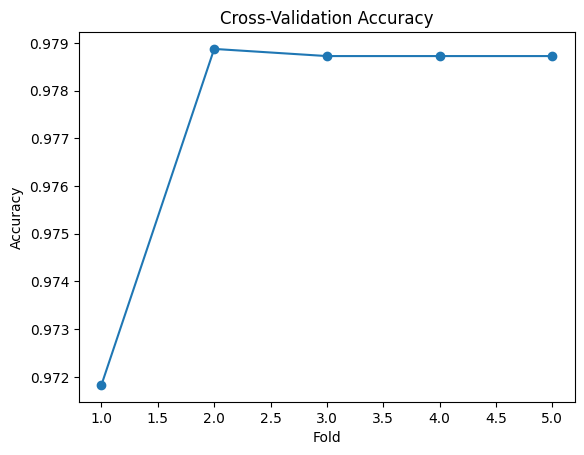

In [25]:
scores = cross_val_score(stack_model, X, y, cv=5)

plt.plot(range(1,6), scores, marker='o')
plt.title("Cross-Validation Accuracy")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.show()

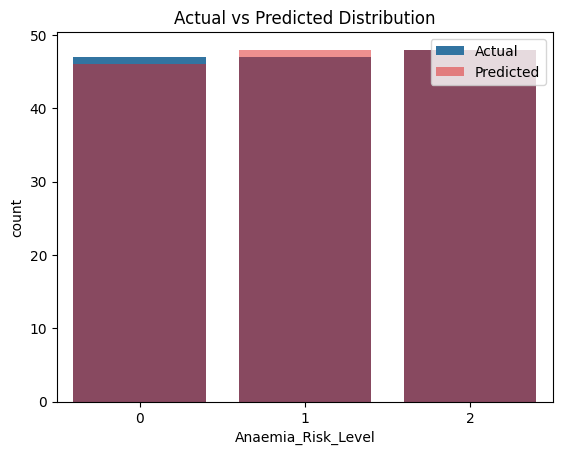

In [26]:
import seaborn as sns

sns.countplot(x=y_test, label="Actual")
sns.countplot(x=y_pred, color='red', alpha=0.5, label="Predicted")

plt.legend()
plt.title("Actual vs Predicted Distribution")
plt.show()

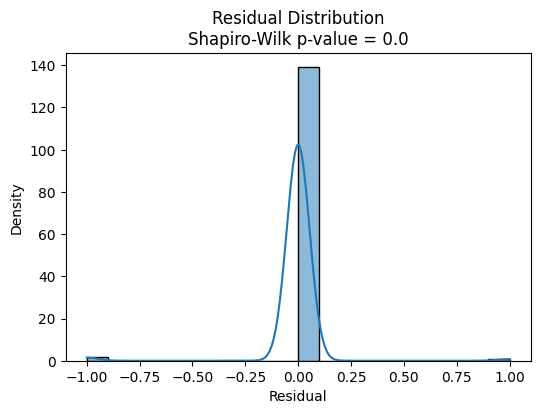

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro

# Predictions
y_pred = stack_model.predict(X_test)

# Residuals
residuals = y_test - y_pred

plt.figure(figsize=(6,4))
sns.histplot(residuals, kde=True, bins=20)

# Statistical test
stat, p = shapiro(residuals)

plt.title(f"Residual Distribution\nShapiro-Wilk p-value = {round(p,4)}")
plt.xlabel("Residual")
plt.ylabel("Density")

plt.show()

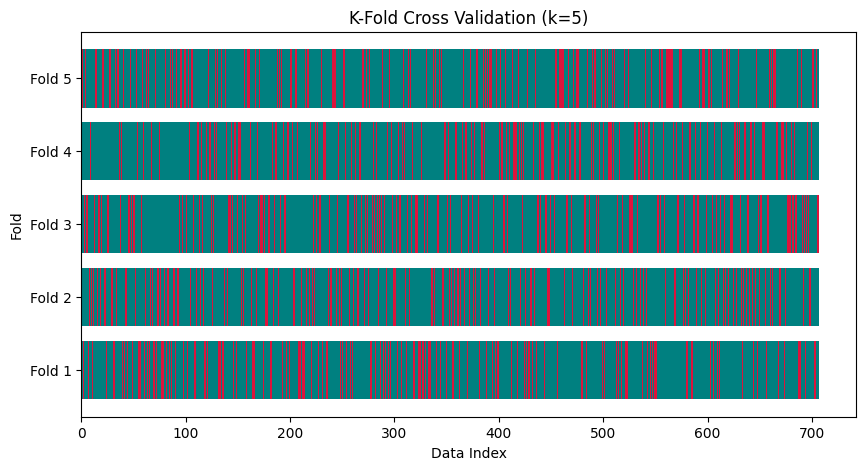

In [32]:
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)

plt.figure(figsize=(10,5))

for i, (train_index, val_index) in enumerate(kf.split(X)):
    y_vals = np.zeros(len(X))
    y_vals[val_index] = 1  # validation

    plt.barh([i]*len(X), [1]*len(X), left=range(len(X)),
             color=['teal' if v==0 else 'crimson' for v in y_vals])

plt.yticks(range(5), [f"Fold {i+1}" for i in range(5)])
plt.title("K-Fold Cross Validation (k=5)")
plt.xlabel("Data Index")
plt.ylabel("Fold")

plt.show()